# Diabetes Health Indicators — Simplified

BRFSS 2021 binary classification: Diabetes_binary (0 = no diabetes/prediabetes, 1 = diabetes).

Steps: EDA → balance the training data → XGBoost vs. Logistic Regression.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TARGET = "Diabetes_binary"
pd.set_option("display.max_columns", None)

## 1. Load data
Columns are stored as floats, so they are cast to `int`.

In [2]:
df = pd.read_csv('diabetes_binary_BRFSS2021_cleaned.csv').astype(int)
print("Original shape:", df.shape)
display(df.head())

Original shape: (223243, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,0,1,1,15,1,0,0,0,1,1,0,1,0,5,10,20,0,0,11,4,5
1,1,1,0,1,28,0,0,1,0,1,0,0,1,0,2,0,0,0,0,11,4,3
2,1,1,1,1,33,0,0,0,1,1,1,0,1,0,2,10,0,0,0,9,4,7
3,1,0,1,1,29,0,1,1,1,1,1,0,1,0,5,0,30,1,1,12,3,4
4,0,0,0,1,24,1,0,0,0,0,0,0,1,0,3,0,0,1,1,13,5,6


## 2. Data quality

In [3]:
print("Missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe().T)

Missing values: 0
Exact duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,223243.0,0.149590,0.356670,0.0,0.0,0.0,0.0,1.0
HighBP,223243.0,0.431642,0.495306,0.0,0.0,0.0,1.0,1.0
HighChol,223243.0,0.410812,0.491982,0.0,0.0,0.0,1.0,1.0
CholCheck,223243.0,0.961450,0.192520,0.0,1.0,1.0,1.0,1.0
BMI,223243.0,29.134414,6.646068,12.0,25.0,28.0,32.0,99.0
Smoker,223243.0,0.426213,0.494527,0.0,0.0,0.0,1.0,1.0
Stroke,223243.0,0.041175,0.198695,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,223243.0,0.091174,0.287857,0.0,0.0,0.0,0.0,1.0
PhysActivity,223243.0,0.766864,0.422829,0.0,1.0,1.0,1.0,1.0
Fruits,223243.0,0.607643,0.488277,0.0,0.0,1.0,1.0,1.0


No missing values. 13,135 exact duplicates (5.6%), removed so the same row can't be in both train and test.

In [4]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

FEATURES = [c for c in df.columns if c != TARGET]
X = df[FEATURES]
y = df[TARGET]

print("Shape after removing duplicates:", df.shape)
print("Diabetes rate:", round(y.mean() * 100, 2), "%")
print(y.value_counts().rename(index={0: "No diabetes", 1: "Diabetes"}))

Shape after removing duplicates: (223243, 22)
Diabetes rate: 14.96 %
Diabetes_binary
No diabetes    189848
Diabetes        33395
Name: count, dtype: int64


## 3. Target distribution

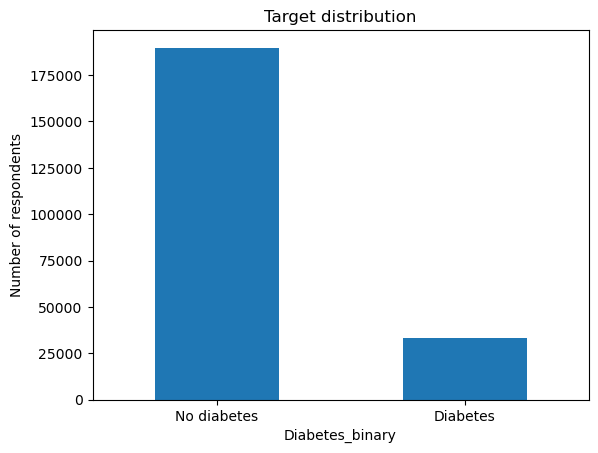

In [5]:
# Target balance
y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
plt.ylabel("Number of respondents")
plt.title("Target distribution")
plt.show()

Imbalanced (85% / 15%), so accuracy is misleading. The training data is balanced in section 8.

## 4. Univariate analysis

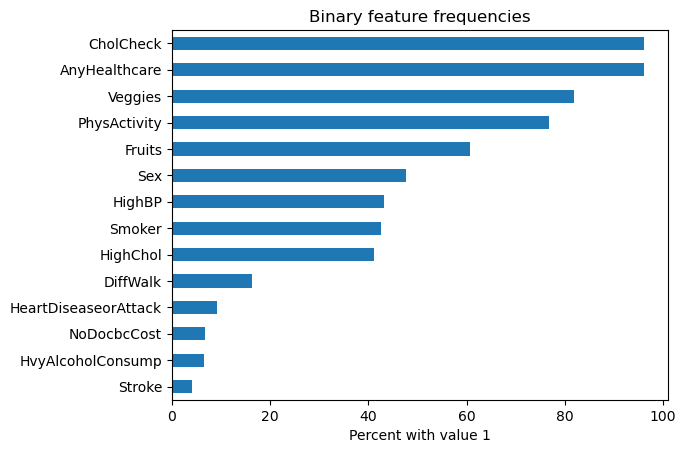

In [6]:
# Percentage of respondents with value 1 for binary features
binary_features = [
    "HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
    "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]
(df[binary_features].mean().sort_values() * 100).plot(kind="barh")
plt.xlabel("Percent with value 1")
plt.title("Binary feature frequencies")
plt.show()

Near-constant: CholCheck and AnyHealthcare (96% = 1), Stroke (4%), HvyAlcoholConsump (6%).

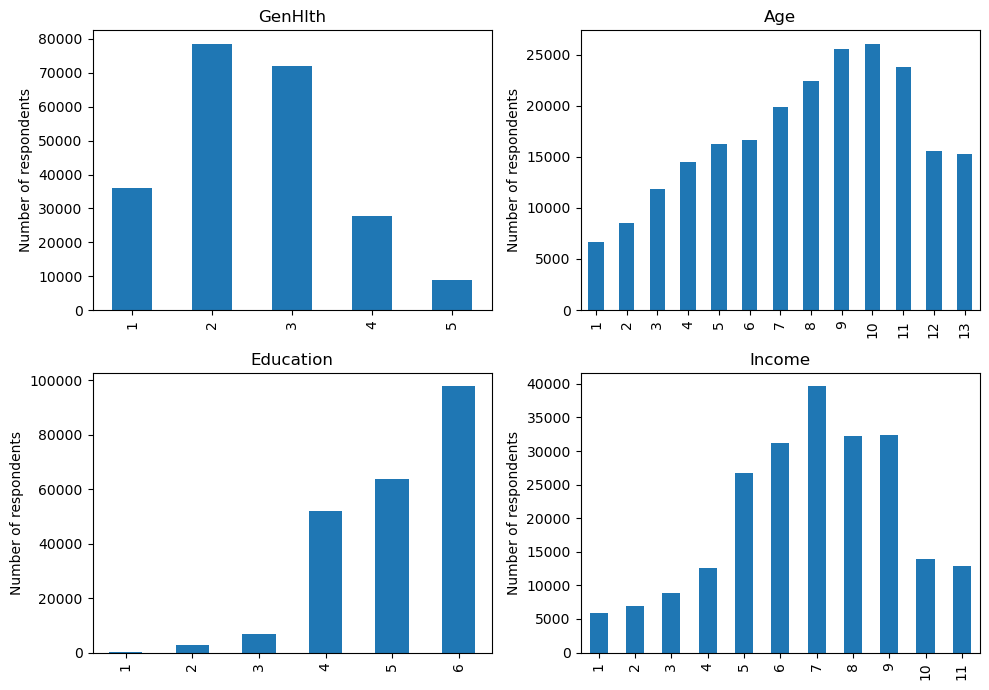

In [7]:
# Distribution of ordinal features
ordinal_features = ["GenHlth", "Age", "Education", "Income"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    df[col].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Number of respondents")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Mostly older (Age 8–11 = 55–74), well-educated respondents. Income peaks at level 7 ($50–75k).

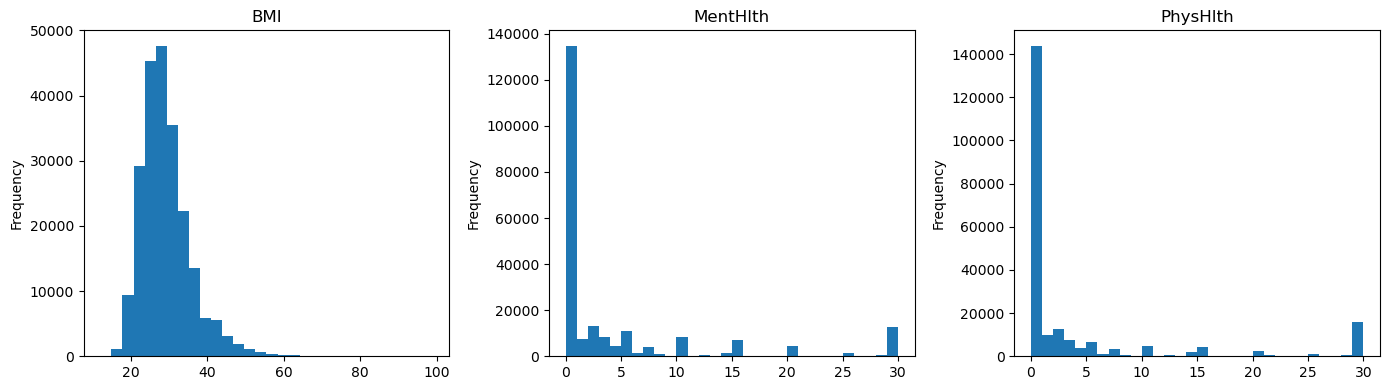

In [8]:
# Distribution of BMI and poor-health days
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    df[col].plot(kind="hist", bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

BMI is right-skewed (median 28). Values above 70 (124 rows) are kept, because trees are not affected by outliers. Most people report 0 poor-health days.

## 5. Bivariate analysis (feature vs. target)

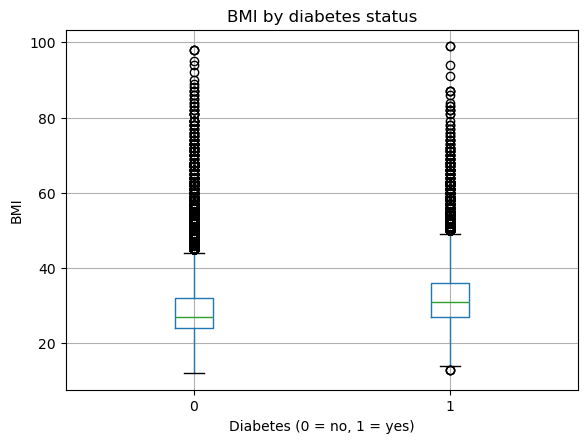

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,,,,,,,,
0,189848.0,28.6,6.4,12.0,24.0,27.0,32.0,98.0
1,33395.0,32.2,7.4,13.0,27.0,31.0,36.0,99.0


In [9]:
# BMI distribution by target
df.boxplot(column="BMI", by=TARGET)
plt.xlabel("Diabetes (0 = no, 1 = yes)")
plt.ylabel("BMI")
plt.title("BMI by diabetes status")
plt.suptitle("")
plt.show()

display(df.groupby(TARGET)["BMI"].describe().round(1))

People with diabetes have a higher BMI (median 31 vs. 27).

BMI_category
Underweight     6.04
Normal          6.85
Overweight     12.41
Obesity I      18.75
Obesity II     24.16
Obesity III    30.31
Name: diabetes_rate_%, dtype: float64

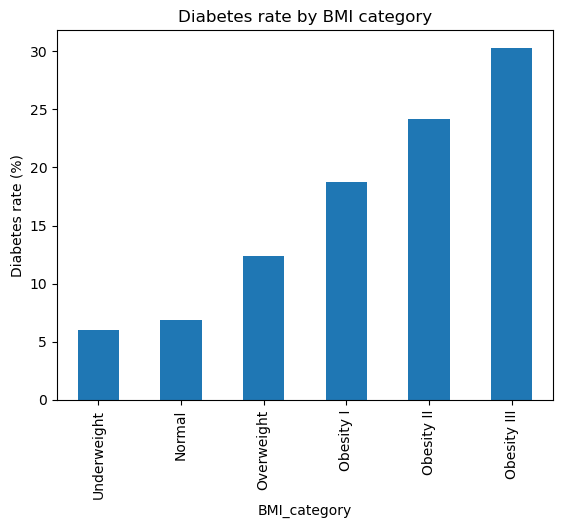

In [10]:
# BMI category and diabetes rate
df["BMI_category"] = pd.cut(
    df["BMI"], bins=[0, 18.5, 25, 30, 35, 40, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obesity I", "Obesity II", "Obesity III"],
    right=False
)
display((df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).rename("diabetes_rate_%").round(2))
(df.groupby("BMI_category", observed=True)[TARGET].mean() * 100).plot(kind="bar")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by BMI category")
plt.show()

The rate rises from about 7% (normal) to 30% (obesity III).

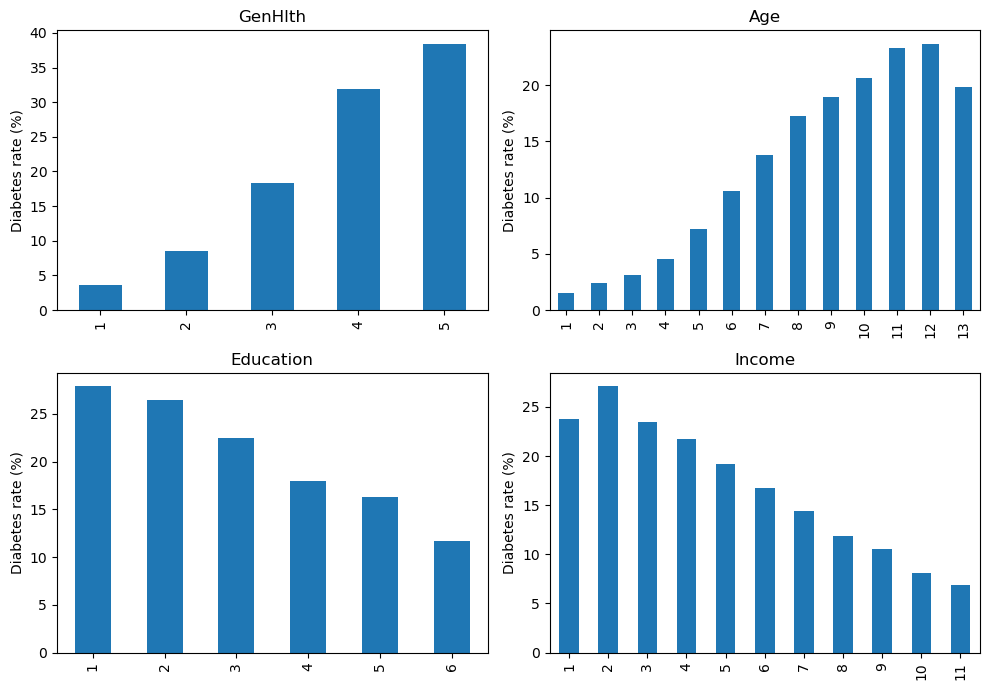

In [11]:
# Diabetes rate by each ordinal feature
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.flat, ordinal_features):
    (df.groupby(col, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_ylabel("Diabetes rate (%)")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

- The rate rises with worse general health (4% → 38%) and with age (peak 24% at 75–79).
- It falls with education (28% → 12%) and income (27% → 7%).

,rate_when_0_%,rate_when_1_%
feature,,
HeartDiseaseorAttack,13.03,34.21
Stroke,14.23,31.82
DiffWalk,11.77,31.37
HighBP,7.01,25.43
HighChol,9.17,23.26
Smoker,13.51,16.91
Sex,13.71,16.34
NoDocbcCost,14.88,15.99
CholCheck,1.94,15.48


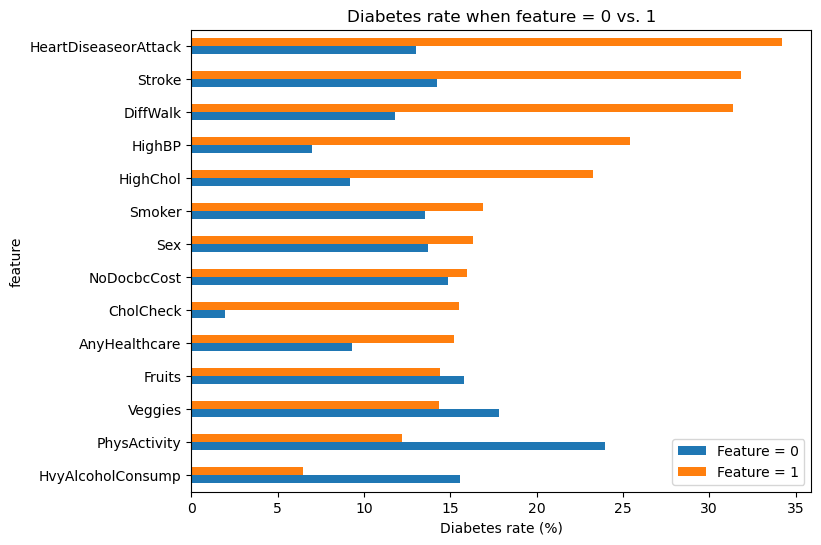

In [12]:
# Diabetes rate for feature values 0 and 1
rows = []
for col in binary_features:
    rates = df.groupby(col)[TARGET].mean()
    rows.append({
        "feature": col,
        "rate_when_0_%": rates.get(0, np.nan) * 100,
        "rate_when_1_%": rates.get(1, np.nan) * 100
    })

binary_rates = pd.DataFrame(rows).set_index("feature")
display(binary_rates.round(2).sort_values("rate_when_1_%", ascending=False))

binary_rates.sort_values("rate_when_1_%").plot(kind="barh", figsize=(8, 6))
plt.xlabel("Diabetes rate (%)")
plt.title("Diabetes rate when feature = 0 vs. 1")
plt.legend(["Feature = 0", "Feature = 1"])
plt.show()

- Strongest: HeartDiseaseorAttack, Stroke, DiffWalk, HighBP, HighChol (2.2–3.6× higher rate when = 1).
- PhysActivity and HvyAlcoholConsump go with lower rates.

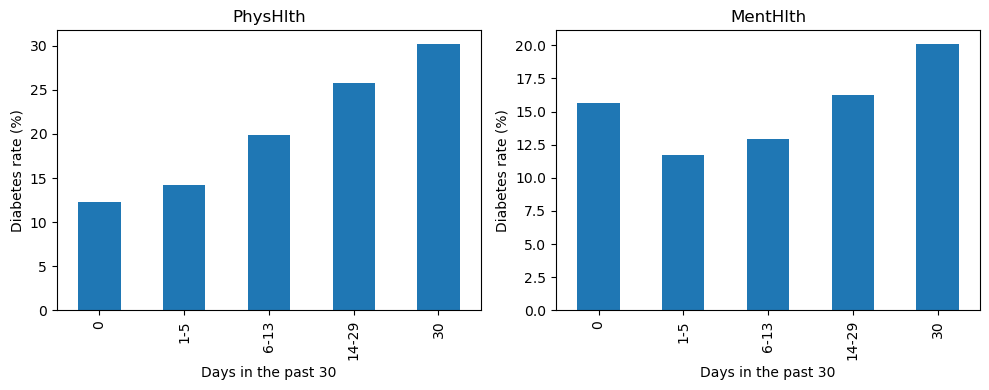

In [13]:
# Diabetes rate by number of poor-health days
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["PhysHlth", "MentHlth"]):
    days = pd.cut(df[col], bins=[-1, 0, 5, 13, 29, 30], labels=["0", "1-5", "6-13", "14-29", "30"])
    (df.groupby(days, observed=True)[TARGET].mean() * 100).plot(kind="bar", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Days in the past 30")
    ax.set_ylabel("Diabetes rate (%)")
plt.tight_layout()
plt.show()

PhysHlth matters (12% → 30%). MentHlth is weak and not steady.

## 6. Correlation

GenHlth                 0.265
HighBP                  0.256
DiffWalk                0.203
HighChol                0.194
BMI                     0.193
Age                     0.192
HeartDiseaseorAttack    0.171
Income                 -0.139
PhysActivity           -0.139
PhysHlth                0.128
Stroke                  0.098
Education              -0.089
CholCheck               0.073
HvyAlcoholConsump      -0.063
Smoker                  0.047
Veggies                -0.038
Sex                     0.037
AnyHealthcare           0.032
Fruits                 -0.019
MentHlth               -0.009
NoDocbcCost             0.008
Name: Diabetes_binary, dtype: float64

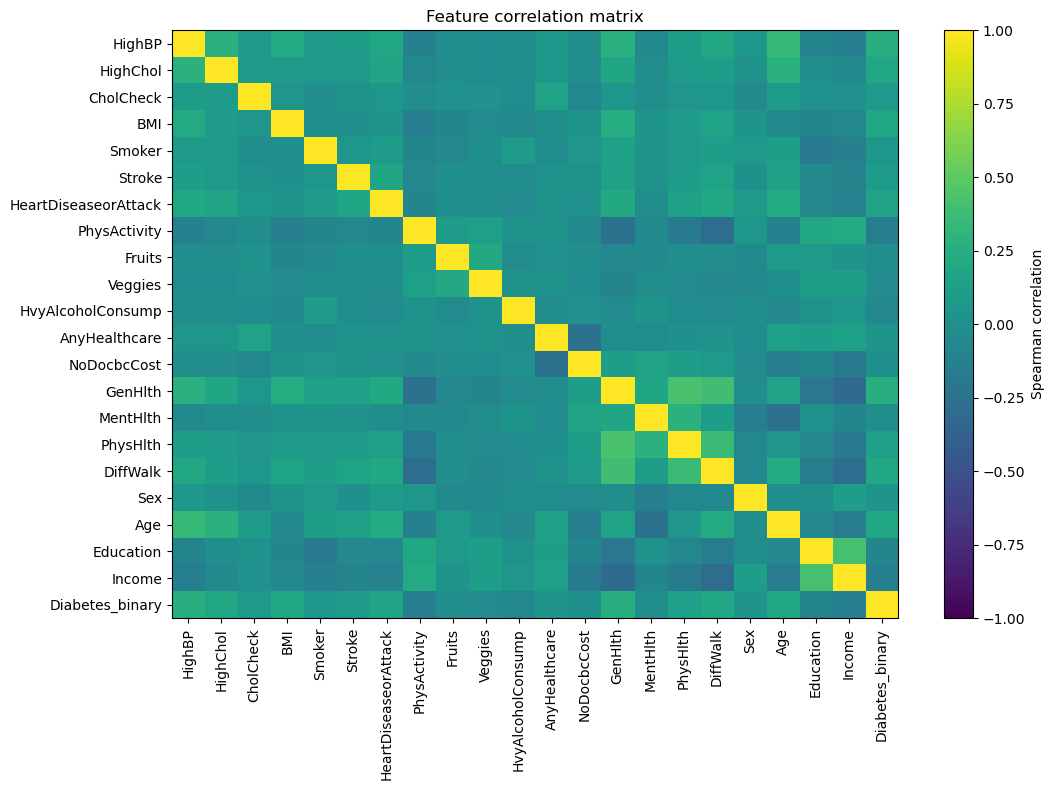

In [14]:
# Spearman correlations
corr = df[FEATURES + [TARGET]].corr(method="spearman")
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

plt.figure(figsize=(11, 8))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Spearman correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Feature correlation matrix")
plt.tight_layout()
plt.show()

Correlations with the target are modest (max 0.265, GenHlth and HighBP). No feature pair is above 0.42, so there's no multicollinearity.

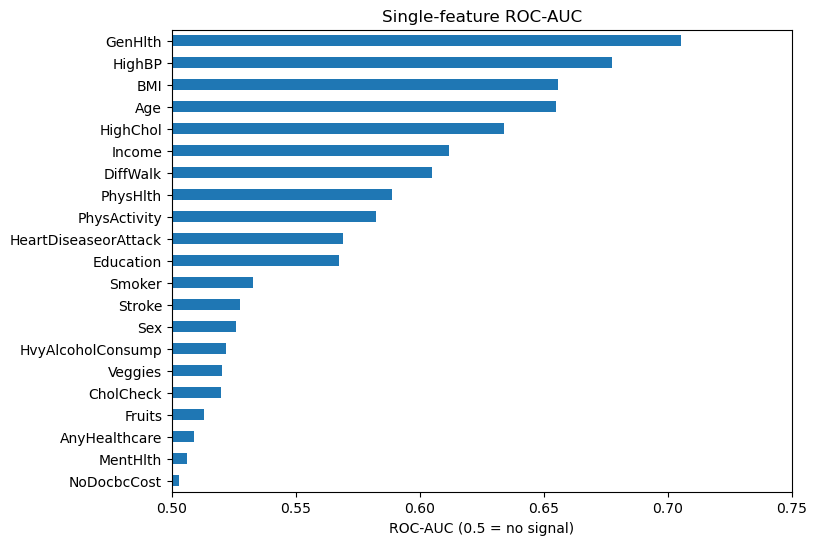

In [15]:
# Leakage check: ROC-AUC of each feature on its own
auc = pd.Series({c: roc_auc_score(df[TARGET], df[c]) for c in FEATURES})
auc = np.maximum(auc, 1 - auc).sort_values()   # strength in either direction
auc.plot(kind="barh", figsize=(8, 6), xlim=(0.5, 0.75))
plt.xlabel("ROC-AUC (0.5 = no signal)")
plt.title("Single-feature ROC-AUC")
plt.show()

The best single feature (GenHlth) reaches only 0.70, so there's no leakage.

## 7. Multivariate analysis

,count,diabetes_rate
condition_count,,
0,86010,4.61
1,73357,13.48
2,49209,27.80
3,12825,38.85
4,1842,47.88


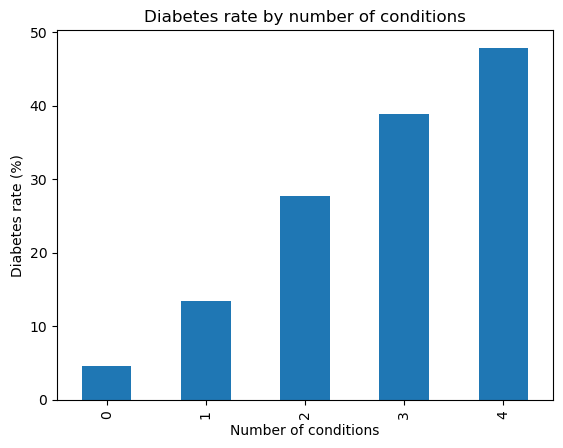

In [16]:
# Number of cardiometabolic conditions
conditions = ["HighBP", "HighChol", "HeartDiseaseorAttack", "Stroke"]
df["condition_count"] = df[conditions].sum(axis=1)
display(df.groupby("condition_count")[TARGET].agg(["count", "mean"]).rename(columns={"mean": "diabetes_rate"}).assign(
    diabetes_rate=lambda x: (x["diabetes_rate"] * 100).round(2)
))
(df.groupby("condition_count")[TARGET].mean() * 100).plot(kind="bar")
plt.xlabel("Number of conditions")
plt.ylabel("Diabetes rate (%)")
plt.title("Diabetes rate by number of conditions")
plt.show()

The rate rises with each extra condition: 5% (none) → 48% (all four).

BMI_category,Underweight,Normal,Overweight,Obesity I,Obesity II,Obesity III
Age,,,,,,
18-39,1.3,1.3,1.8,3.7,6.0,11.3
40-49,5.1,3.2,5.3,10.4,14.6,22.9
50-59,7.6,6.3,11.1,18.0,25.5,34.0
60-69,8.0,8.5,15.7,24.5,32.2,42.1
70+,7.9,12.2,20.6,29.5,38.5,45.0


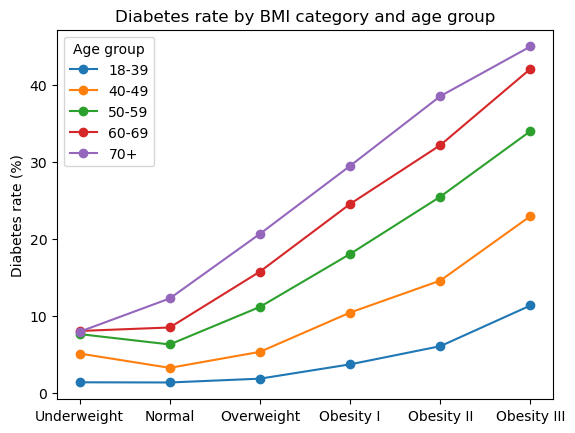

In [17]:
# Age group x BMI category
age_group = pd.cut(df["Age"], bins=[0, 4, 6, 8, 10, 13], labels=["18-39", "40-49", "50-59", "60-69", "70+"])
age_bmi = pd.crosstab(age_group, df["BMI_category"], values=df[TARGET], aggfunc="mean") * 100
display(age_bmi.round(1))

age_bmi.T.plot(marker="o")
plt.ylabel("Diabetes rate (%)")
plt.xlabel("")
plt.title("Diabetes rate by BMI category and age group")
plt.legend(title="Age group")
plt.show()

Age and BMI add up: about 1% (18–39, normal BMI) → 45% (70+, obesity III).

## 8. Balance the dataset
- Split first (80/20, stratified).
- Then undersample the training set: keep all diabetes rows and the same number of random no-diabetes rows.
- The test set keeps the real 85/15 ratio, so test scores stay honest.

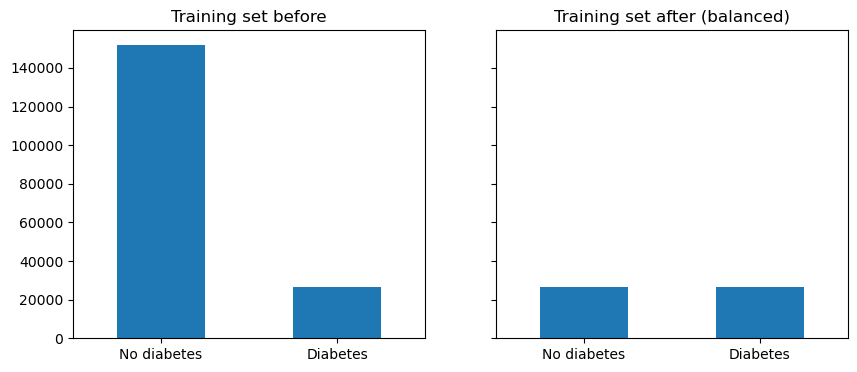

Train before: {0: 151878, 1: 26716}
Train after:  {0: 26716, 1: 26716}
Test (unchanged): {0: 37970, 1: 6679}


In [18]:
# Split (original 21 features only)
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# Random undersampling of the training set
train = pd.concat([X_train, y_train], axis=1)
n_diabetes = (train[TARGET] == 1).sum()
train_bal = pd.concat([
    train[train[TARGET] == 1],
    train[train[TARGET] == 0].sample(n_diabetes, random_state=RANDOM_STATE)
]).sample(frac=1, random_state=RANDOM_STATE)   # shuffle
X_train_bal, y_train_bal = train_bal[FEATURES], train_bal[TARGET]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
y_train.value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Training set before")
y_train_bal.value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Training set after (balanced)")
for ax in axes:
    ax.set_xticks([0, 1], ["No diabetes", "Diabetes"], rotation=0)
    ax.set_xlabel("")
plt.show()

print("Train before:", y_train.value_counts().to_dict())
print("Train after: ", y_train_bal.value_counts().to_dict())
print("Test (unchanged):", y_test.value_counts().to_dict())

## 9. Modelling
Each model gets a 5-fold CV ROC-AUC on its training data and is then scored on the real test set (threshold 0.5).

In [19]:
import xgboost as xgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, ConfusionMatrixDisplay)

results = {}   # name -> scores
probas = {}    # name -> predicted probabilities on the test set

def evaluate(name, model, X_tr, y_tr):
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=5, scoring="roc_auc").mean()
    model.fit(X_tr, y_tr)
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {
        "CV ROC-AUC": cv_auc,
        "Test ROC-AUC": roc_auc_score(y_test, proba),
        "Test PR-AUC": average_precision_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
    }
    probas[name] = proba
    return pd.DataFrame(results).T.round(3)

### 9.1 XGBoost on the original (imbalanced) data
For comparison only: this shows why balancing is needed.

In [20]:
evaluate("XGBoost - imbalanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train, y_train)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.81,0.409,0.16,0.532,0.246,0.853


High accuracy (85%), but recall is only 16%: it misses most diabetics.

### 9.2 XGBoost on the balanced data

In [21]:
evaluate("XGBoost - balanced", xgb.XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702


Recall jumps to 78% and F1 from 0.25 to 0.44. Precision drops, as expected.

### 9.3 XGBoost, balanced + better settings
Slower learning, smaller trees and subsampling, to reduce overfitting.

In [22]:
xgb_model = xgb.XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                              subsample=0.8, colsample_bytree=0.8,
                              random_state=RANDOM_STATE, n_jobs=-1)
evaluate("XGBoost - balanced + settings", xgb_model, X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703


Best model: ROC-AUC rises from 0.806 to 0.814, and PR-AUC from 0.402 to 0.420.

### 9.4 Comparison model: Logistic Regression
A simple linear baseline (scaled features), trained on the same balanced data.

In [23]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
evaluate("Logistic Regression - balanced", log_reg, X_train_bal, y_train_bal)

/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716


## 10. Results

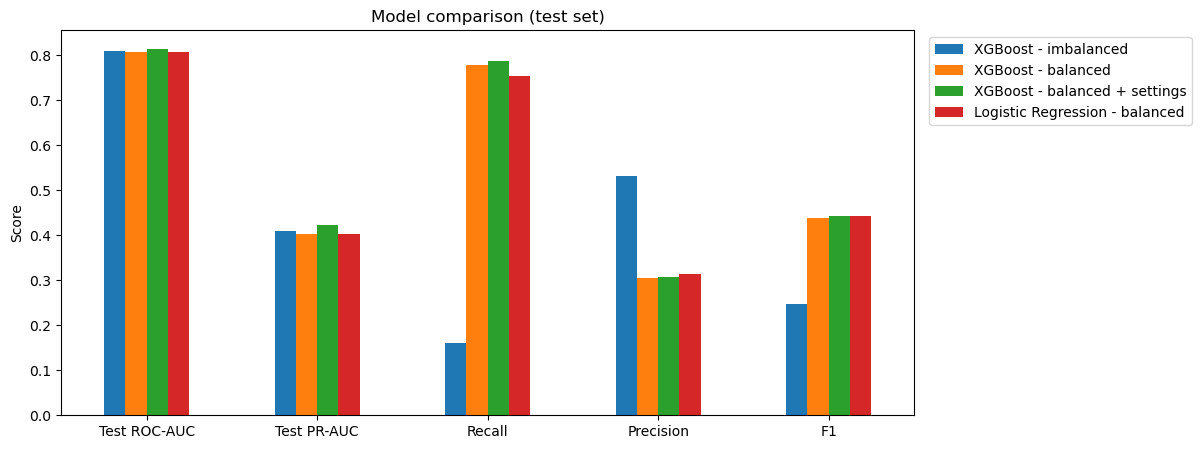

In [24]:
# Compare the models on the test set
metrics = ["Test ROC-AUC", "Test PR-AUC", "Recall", "Precision", "F1"]
pd.DataFrame(results).loc[metrics].plot(kind="bar", figsize=(11, 5))
plt.xticks(rotation=0)
plt.ylabel("Score")
plt.title("Model comparison (test set)")
plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

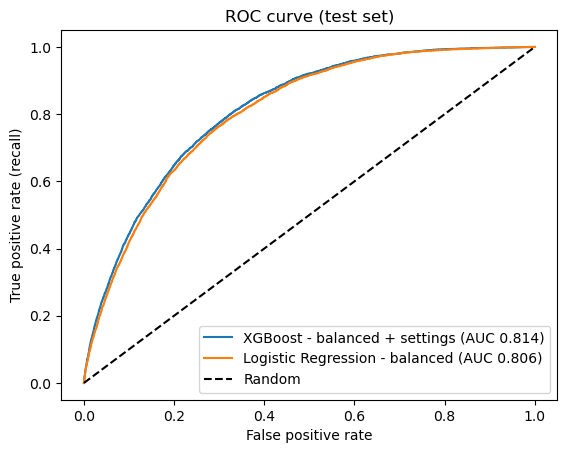

In [25]:
# ROC curves: best XGBoost vs. Logistic Regression
for name in ["XGBoost - balanced + settings", "Logistic Regression - balanced"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {results[name]['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

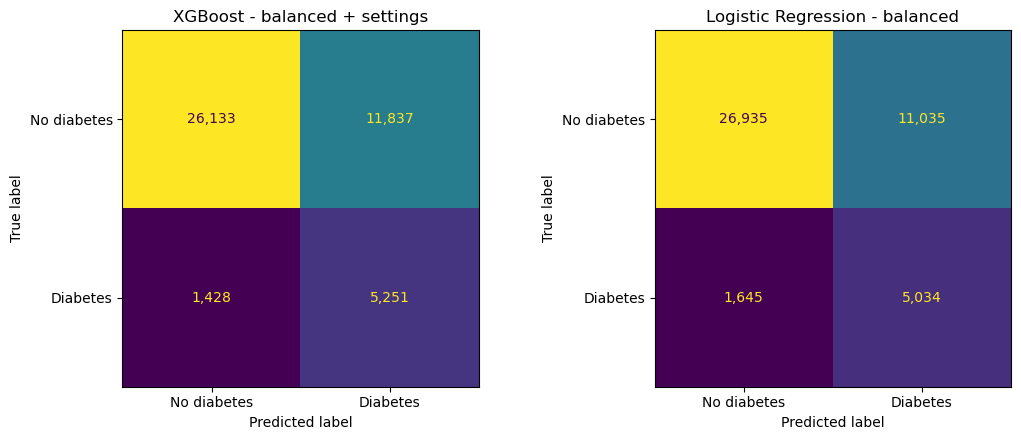

In [26]:
# Confusion matrices (test set)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, ["XGBoost - balanced + settings", "Logistic Regression - balanced"]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probas[name] >= 0.5).astype(int),
                                            display_labels=["No diabetes", "Diabetes"],
                                            ax=ax, colorbar=False, values_format=",")
    ax.set_title(name)
plt.tight_layout()
plt.show()

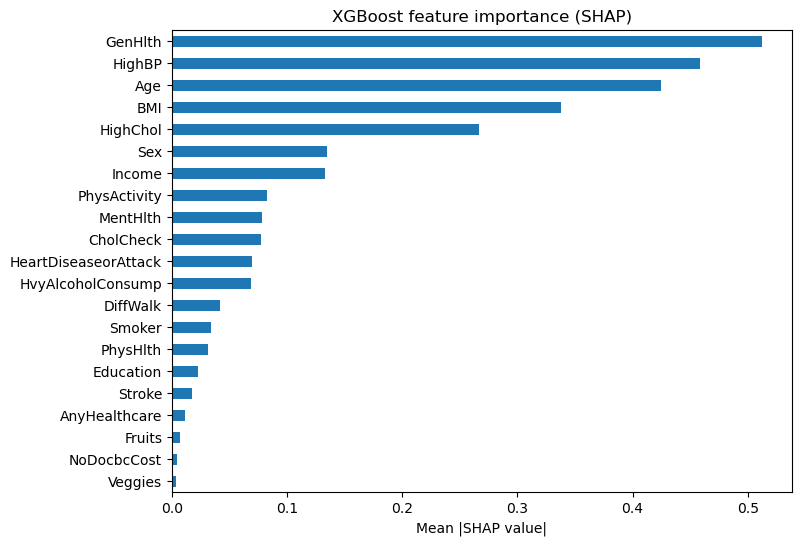

In [27]:
# Feature importance (best XGBoost): mean |SHAP value| on the test set
shap_values = xgb_model.get_booster().predict(xgb.DMatrix(X_test), pred_contribs=True)[:, :-1]   # last column = bias
pd.Series(np.abs(shap_values).mean(axis=0), index=FEATURES).sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Mean |SHAP value|")
plt.title("XGBoost feature importance (SHAP)")
plt.show()

## 11. Conclusion
- Balancing the training data was the biggest improvement: recall went from 16% to 78%.
- Best model: XGBoost (balanced + settings). Test ROC-AUC 0.814, PR-AUC 0.420, recall 79%, F1 0.44.
- Logistic Regression is close: same F1 (0.44), but lower ROC-AUC (0.806), PR-AUC (0.402) and recall (75%).
- Top features (SHAP): GenHlth, HighBP, Age, BMI, HighChol.

## Gradient Boosting Classifier

In [28]:
from sklearn.ensemble import GradientBoostingClassifier

gb_imbalanced = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - imbalanced",
    gb_imbalanced,
    X_train,
    y_train
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855


The Gradient Boosting model achieved 85.5% accuracy, but the recall was only 15.8%. This means the model missed most diabetes cases. The results show that high accuracy does not always mean the model performs well.

In [29]:
gb_balanced = GradientBoostingClassifier(
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - balanced",
    gb_balanced,
    X_train_bal,
    y_train_bal
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703


Using balanced data improved the model's recall from 15.8% to 78.1%, helping it detect more diabetes cases. However, precision decreased to 30.7%, meaning the model made more false positive predictions.

In [30]:
gb_tuned = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    random_state=RANDOM_STATE
)

evaluate(
    "Gradient Boosting - balanced + settings",
    gb_tuned,
    X_train_bal,
    y_train_bal
)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703




Changing the model settings slightly improved recall from 78.1% to 78.5%. However, the F1 score stayed the same at 0.441, so the improvement was very small.

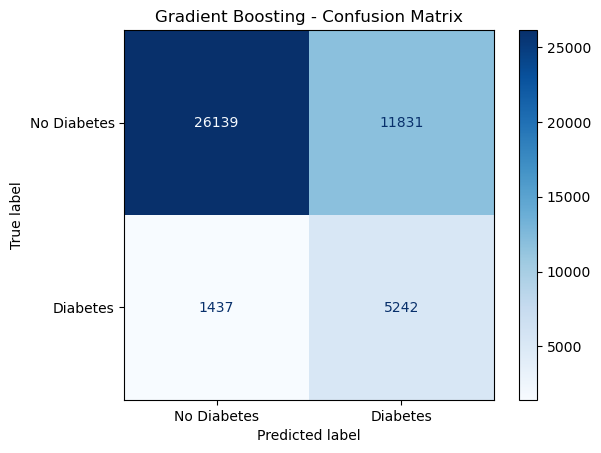

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

gb_predictions = (probas["Gradient Boosting - balanced + settings"] >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)

plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

The model correctly detected 5,242 diabetes cases but missed 1,437 cases. It achieved 78.5% recall, but also made many false positive predictions.

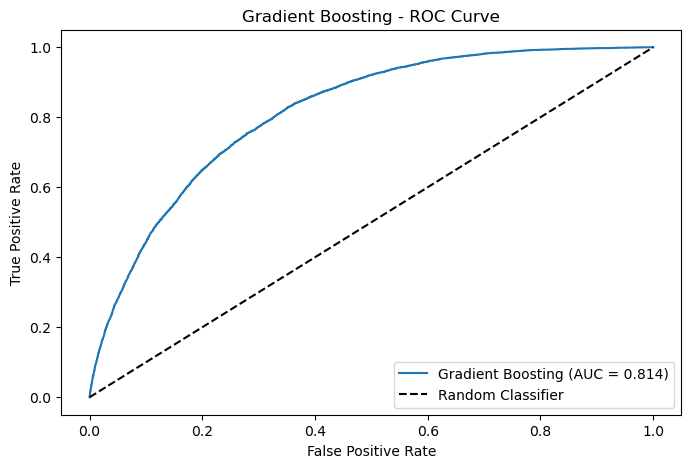

In [32]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

gb_probs = probas["Gradient Boosting - balanced + settings"]

fpr, tpr, thresholds = roc_curve(y_test, gb_probs)
auc_score = roc_auc_score(y_test, gb_probs)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Gradient Boosting - ROC Curve")
plt.legend()
plt.show()

The Gradient Boosting model achieved a ROC-AUC of 0.814, showing good ability to distinguish between people with and without diabetes. The model performed better than random guessing.

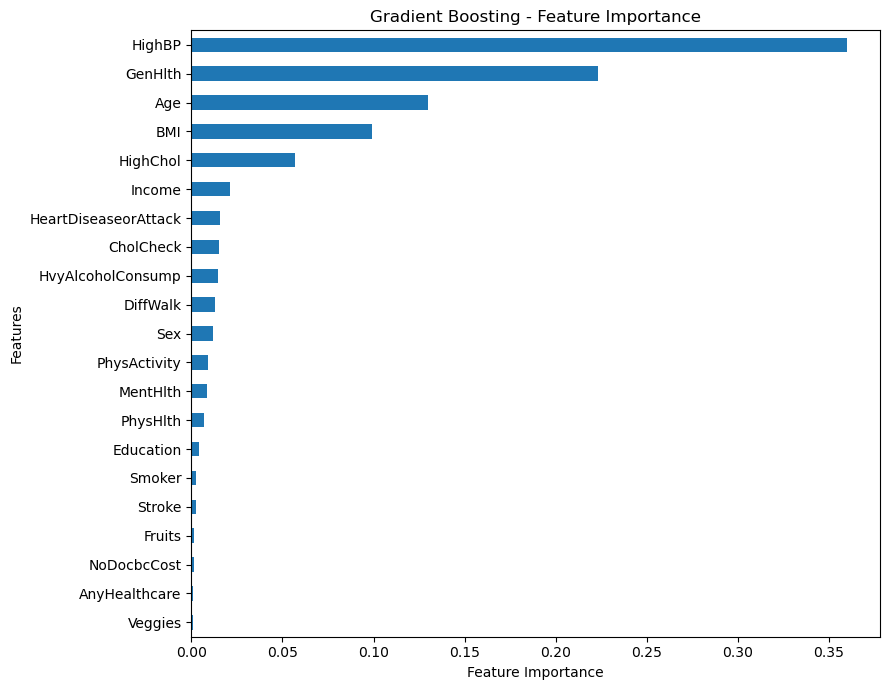

In [33]:
import pandas as pd
import matplotlib.pyplot as plt

gb_importance = pd.Series(
    gb_tuned.feature_importances_,
    index=X_train_bal.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 7))

gb_importance.plot(kind="barh")

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("Gradient Boosting - Feature Importance")

plt.tight_layout()
plt.show()

The most important features were HighBP, GenHlth, Age, BMI, and HighChol. HighBP had the highest importance, meaning the model relied on it the most when making predictions.

In [34]:
import pandas as pd

# Gradient Boosting experiments
gb_names = [
    "Gradient Boosting - imbalanced",
    "Gradient Boosting - balanced",
    "Gradient Boosting - balanced + settings"
]

# Create comparison table
gb_comparison = pd.DataFrame(results).T

# Select Gradient Boosting experiments
gb_comparison = gb_comparison.reindex(gb_names)

# Display results
display(gb_comparison.round(3))

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703


Balancing the training data improved the model's recall from 15.8% to 78.1%. Changing the settings increased recall slightly to 78.5%, but the F1 score stayed the same at 0.441. The tuned balanced model detected the most diabetes cases, but it still produced many false positives.

## 12. Tuned cut-off
All models use a cut-off of 0.5. They were trained on 50/50 data, so 0.5 flags too many people.
We pick a better cut-off on a validation set taken from the training data (real 85/15 ratio), then check it once on the test set.

In [35]:
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve

# validation set from the training data, keeps the real 85/15 ratio
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)

# undersample the fitting part the same way as section 8
fit = pd.concat([X_fit, y_fit], axis=1)
n_diabetes_fit = (fit[TARGET] == 1).sum()
fit_bal = pd.concat([
    fit[fit[TARGET] == 1],
    fit[fit[TARGET] == 0].sample(n_diabetes_fit, random_state=RANDOM_STATE)
]).sample(frac=1, random_state=RANDOM_STATE)
X_fit_bal, y_fit_bal = fit_bal[FEATURES], fit_bal[TARGET]

def best_cutoff(model):
    # train a copy on the balanced part, then take the cut-off with the best F1 on validation
    m = clone(model).fit(X_fit_bal, y_fit_bal)
    precision, recall, cuts = precision_recall_curve(y_val, m.predict_proba(X_val)[:, 1])
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return cuts[np.argmax(f1[:-1])]

cutoffs = {
    "XGBoost - balanced + settings": best_cutoff(xgb_model),
    "Gradient Boosting - balanced + settings": best_cutoff(gb_tuned),
    "Logistic Regression - balanced": best_cutoff(log_reg),
}
for name, cut in cutoffs.items():
    print(name, "-> best cut-off:", round(float(cut), 3))


XGBoost - balanced + settings -> best cut-off: 0.624
Gradient Boosting - balanced + settings -> best cut-off: 0.63
Logistic Regression - balanced -> best cut-off: 0.567


/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/opt/homebrew/Caskroom/miniconda/base/envs/ai/lib/python3.12/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWar

In [36]:
# same models and test probabilities as before, only the cut-off changes
rows = {}
for name, cut in cutoffs.items():
    for label, c in [("0.5", 0.5), ("tuned", cut)]:
        pred = (probas[name] >= c).astype(int)
        rows[f"{name.split(' -')[0]}, cut-off {c:.2f}"] = {
            "Recall": recall_score(y_test, pred),
            "Precision": precision_score(y_test, pred),
            "F1": f1_score(y_test, pred),
            "Accuracy": accuracy_score(y_test, pred),
        }
display(pd.DataFrame(rows).T.round(3))


,Recall,Precision,F1,Accuracy
"XGBoost, cut-off 0.50",0.786,0.307,0.442,0.703
"XGBoost, cut-off 0.62",0.637,0.366,0.464,0.780
"Gradient Boosting, cut-off 0.50",0.785,0.307,0.441,0.703
"Gradient Boosting, cut-off 0.63",0.634,0.369,0.466,0.783
"Logistic Regression, cut-off 0.50",0.754,0.313,0.443,0.716
"Logistic Regression, cut-off 0.57",0.675,0.342,0.454,0.757


The best cut-offs are 0.62 (XGBoost), 0.63 (Gradient Boosting) and 0.57 (Logistic Regression).
- F1 rises from 0.44 to 0.46 for XGBoost, to 0.47 for Gradient Boosting and to 0.45 for Logistic Regression. Precision rises from about 0.31 to 0.34–0.37.
- Recall drops from 0.79 to 0.64 for the tree models, and from 0.75 to 0.68 for Logistic Regression: the models find fewer diabetics, but more of their flags are right.
- Logistic Regression finds a few more diabetics (recall 0.68), but with lower precision (0.34), so its F1 stays below XGBoost.
- ROC-AUC and PR-AUC do not change, because the cut-off does not change how the model ranks people.
- For screening, where finding diabetics matters most, the 0.5 cut-off with its higher recall can still be the better choice.

## 13. More survey columns (CDC BRFSS 2021)
Every model stops at about 0.815 ROC-AUC with the 21 features. The 21 features come from a much bigger CDC survey (303 columns per person),
so we rebuild the same data from the original file, add more columns, and compare on the same people.
- Source: [CDC BRFSS 2021](https://www.cdc.gov/brfss/annual_data/annual_2021.html), file `LLCP2021XPT.zip`, unzipped next to this notebook.
- Left out on purpose: anything about diabetes care or caused by the diagnosis (insulin, A1C, blood sugar tests, prediabetes, cholesterol and blood pressure medicine, check-ups, pneumonia shot).

In [37]:
# load the original CDC file (438,693 people)
CDC_FILE = "LLCP2021.XPT"
cdc = pd.read_sas(CDC_FILE, format="xport")
print(cdc.shape)

def yes_no(col):
    # 1 = yes, 2 = no, don't know / refused = missing
    return cdc[col].map({1: 1, 2: 0})

def only(col, values):
    return cdc[col].where(cdc[col].isin(values))

def days(col):
    # 88 = none, 77 / 99 = don't know / refused
    return cdc[col].replace(88, 0).where(lambda s: s <= 30)

# rebuild the target and the 21 features the same way as the Kaggle file
new = pd.DataFrame({
    TARGET: cdc["DIABETE4"].map({1: 1, 2: 0, 3: 0, 4: 0}),   # yes / only in pregnancy / no / prediabetes
    "HighBP": cdc["_RFHYPE6"].map({1: 0, 2: 1}),
    "HighChol": cdc["_RFCHOL3"].map({1: 0, 2: 1}),
    "CholCheck": cdc["_CHOLCH3"].map({1: 1, 2: 0, 3: 0}),
    "BMI": (cdc["_BMI5"] / 100).round(),
    "Smoker": yes_no("SMOKE100"),
    "Stroke": yes_no("CVDSTRK3"),
    "HeartDiseaseorAttack": yes_no("_MICHD"),
    "PhysActivity": yes_no("_TOTINDA"),
    "Fruits": yes_no("_FRTLT1A"),
    "Veggies": yes_no("_VEGLT1A"),
    "HvyAlcoholConsump": cdc["_RFDRHV7"].map({1: 0, 2: 1}),
    "AnyHealthcare": yes_no("_HLTHPLN"),
    "NoDocbcCost": yes_no("MEDCOST1"),
    "GenHlth": only("GENHLTH", [1, 2, 3, 4, 5]),
    "MentHlth": days("MENTHLTH"),
    "PhysHlth": days("PHYSHLTH"),
    "DiffWalk": yes_no("DIFFWALK"),
    "Sex": cdc["_SEX"].map({1: 1, 2: 0}),
    "Age": only("_AGEG5YR", range(1, 14)),
    "Education": only("EDUCA", range(1, 7)),
    "Income": only("INCOME3", range(1, 12)),
})


(438693, 303)


In [38]:
# extra columns: new information that is not caused by a diabetes diagnosis
for col in ["CHCKDNY2", "HAVARTH5", "CHCCOPD3", "ADDEPEV3", "ASTHMA3", "CHCSCNCR", "CHCOCNCR",   # kidney, arthritis, COPD, depression, asthma, cancer
            "CVDINFR4", "CVDCRHD4", "DEAF", "BLIND", "DECIDE", "DIFFDRES", "DIFFALON",            # heart attack, heart disease, disabilities
            "VETERAN3", "EXERANY2", "ECIGNOW1"]:
    new[col] = yes_no(col)

new["BPHIGH6"] = only("BPHIGH6", [1, 2, 3, 4])   # high BP: yes / only in pregnancy / no / borderline
new["POORHLTH"] = days("POORHLTH")
new["CHILDREN"] = cdc["CHILDREN"].replace(88, 0).where(lambda s: s <= 87)
new["AGE"] = cdc["_AGE80"]                         # exact age, not 5-year groups
new["HEIGHT_M"] = cdc["HTM4"] / 100
new["WEIGHT_KG"] = cdc["WTKG3"] / 100
new["SMOKER4"] = only("_SMOKER3", [1, 2, 3, 4])
new["DRINKS_WK"] = cdc["_DRNKWK1"].where(lambda s: s < 99900)
new["FRUIT_DAY"] = cdc["FRUTDA2_"] / 100
new["VEG_DAY"] = cdc["VEGEDA2_"] / 100
new["FRIES_DAY"] = cdc["FRNCHDA_"] / 100
new["POTATO_DAY"] = cdc["POTADA1_"] / 100
new["URBAN"] = cdc["_URBSTAT"].map({1: 1, 2: 0})
new["STATE"] = cdc["_STATE"]

# categories without an order become 0/1 columns
categories = {"MARITAL": range(1, 7), "EMPLOY1": range(1, 9), "PRIMINSR": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 88],
              "_IMPRACE": range(1, 7), "RENTHOM1": [1, 2, 3]}
for col, values in categories.items():
    new = new.join(pd.get_dummies(only(col, values), prefix=col.strip("_"), dtype=float))

EXTRA = [c for c in new.columns if c != TARGET and c not in FEATURES]
print(len(EXTRA), "extra columns")


65 extra columns


In [39]:
# same cleaning as the Kaggle file: drop rows with missing answers in the 21 features, then exact duplicates
new = new.dropna(subset=[TARGET] + FEATURES).drop_duplicates(subset=[TARGET] + FEATURES).reset_index(drop=True)
print("rows:", len(new), "| diabetes rate:", round(new[TARGET].mean() * 100, 2), "%")   # same as the cleaned file

X_new = new[FEATURES + EXTRA]
y_new = new[TARGET].astype(int)
Xn_train, Xn_test, yn_train, yn_test = train_test_split(X_new, y_new, test_size=0.2, stratify=y_new, random_state=RANDOM_STATE)

weight = (yn_train == 0).sum() / (yn_train == 1).sum()
cdc_model = xgb.XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=4, min_child_weight=5,
                              subsample=0.8, colsample_bytree=0.8, scale_pos_weight=weight,
                              random_state=RANDOM_STATE, n_jobs=-1)

def score(cols):
    # pick the cut-off on a validation part of the training data, then check the test set once
    Xa, Xv, ya, yv = train_test_split(Xn_train[cols], yn_train, test_size=0.2, stratify=yn_train, random_state=RANDOM_STATE)
    m = clone(cdc_model).fit(Xa, ya)
    precision, recall, cuts = precision_recall_curve(yv, m.predict_proba(Xv)[:, 1])
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    cut = cuts[np.argmax(f1[:-1])]

    m = clone(cdc_model).fit(Xn_train[cols], yn_train)
    proba = m.predict_proba(Xn_test[cols])[:, 1]
    pred = (proba >= cut).astype(int)
    return m, {
        "Columns": len(cols),
        "Test ROC-AUC": roc_auc_score(yn_test, proba),
        "Test PR-AUC": average_precision_score(yn_test, proba),
        "Cut-off": cut,
        "Recall": recall_score(yn_test, pred),
        "Precision": precision_score(yn_test, pred),
        "F1": f1_score(yn_test, pred),
    }

model_21, scores_21 = score(FEATURES)
model_cdc, scores_cdc = score(FEATURES + EXTRA)
display(pd.DataFrame({"21 features": scores_21, "21 + extra CDC columns": scores_cdc}).T.round(3))


rows: 223243 | diabetes rate: 14.96 %


,Columns,Test ROC-AUC,Test PR-AUC,Cut-off,Recall,Precision,F1
21 features,21.0,0.815,0.423,0.616,0.644,0.365,0.466
21 + extra CDC columns,86.0,0.829,0.458,0.630,0.627,0.394,0.484


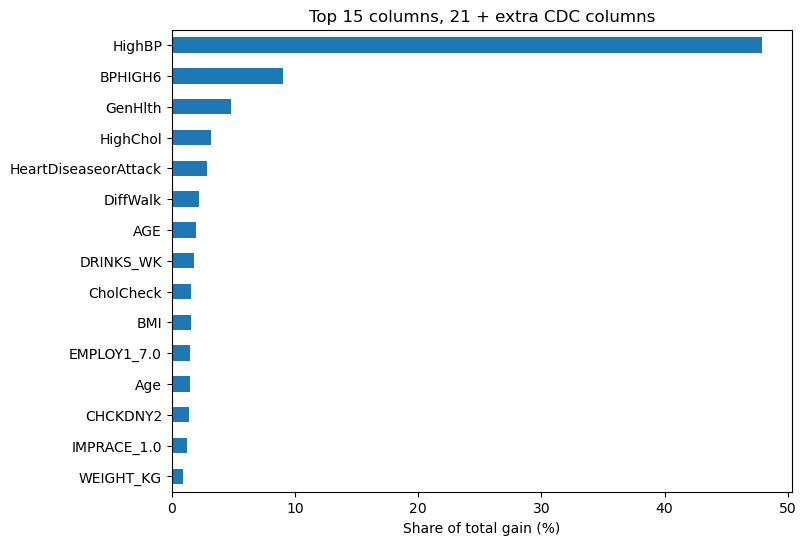

In [40]:
# which columns the new model uses most (share of total gain)
gain = pd.Series(model_cdc.get_booster().get_score(importance_type="gain"))
(gain / gain.sum() * 100).sort_values().tail(15).plot(kind="barh", figsize=(8, 6))
plt.xlabel("Share of total gain (%)")
plt.title("Top 15 columns, 21 + extra CDC columns")
plt.show()


More survey columns is the first change that moves the metrics:
- ROC-AUC rises from 0.815 to 0.829 and PR-AUC from 0.423 to 0.458, on the same people and the same kind of split.
- With a tuned cut-off, F1 rises from 0.466 to 0.484 and precision from 0.37 to 0.39, with almost the same recall (0.63 vs 0.64).
- High blood pressure is still the strongest column. The chart shows which new columns the model uses.
- So the limit was the 21 features, not the model. More information about each person is what improves the score.

## 14. Comparison model: Random Forest
Random Forest also uses many trees, but in a different way:
- XGBoost builds trees one after another. Each new tree fixes the mistakes of the trees before it.
- Random Forest builds every tree on its own, from a random sample of rows and columns. Then the trees vote.

Same split, same balanced training data and same test set as XGBoost.

In [41]:
from sklearn.ensemble import RandomForestClassifier

evaluate("Random Forest - imbalanced", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train, y_train)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703
Random Forest - imbalanced,0.776,0.776,0.352,0.173,0.463,0.252,0.846


High accuracy (84.6%), but recall is only 17.3%: the same trap as XGBoost and Gradient Boosting.
ROC-AUC is also much lower (0.776), because by default every tree memorizes the training rows.

In [42]:
evaluate("Random Forest - balanced", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703
Random Forest - imbalanced,0.776,0.776,0.352,0.173,0.463,0.252,0.846
Random Forest - balanced,0.790,0.791,0.369,0.766,0.294,0.425,0.690


Balancing lifts recall from 17.3% to 76.6% and F1 from 0.25 to 0.43.
ROC-AUC rises to 0.791, but it is still below XGBoost with default settings (0.806).

In [43]:
# by default every tree grows until each leaf has 1 person, so it memorizes the training rows
# pick the smallest leaf size with 5-fold CV on the training data
for leaf in [1, 5, 10, 20, 30]:
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, random_state=RANDOM_STATE, n_jobs=-1)
    print("min_samples_leaf", leaf, "-> CV ROC-AUC", round(cross_val_score(rf, X_train_bal, y_train_bal, cv=5, scoring="roc_auc").mean(), 4))

min_samples_leaf 1 -> CV ROC-AUC 0.7928


min_samples_leaf 5 -> CV ROC-AUC 0.8089


min_samples_leaf 10 -> CV ROC-AUC 0.8101


min_samples_leaf 20 -> CV ROC-AUC 0.8104


min_samples_leaf 30 -> CV ROC-AUC 0.8099


In [44]:
rf_model = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1)
evaluate("Random Forest - balanced + settings", rf_model, X_train_bal, y_train_bal)

,CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Recall,Precision,F1,Accuracy
XGBoost - imbalanced,0.808,0.810,0.409,0.160,0.532,0.246,0.853
XGBoost - balanced,0.804,0.806,0.402,0.777,0.305,0.439,0.702
XGBoost - balanced + settings,0.814,0.814,0.421,0.786,0.307,0.442,0.703
Logistic Regression - balanced,0.807,0.806,0.402,0.754,0.313,0.443,0.716
Gradient Boosting - imbalanced,0.813,0.813,0.422,0.158,0.558,0.246,0.855
Gradient Boosting - balanced,0.813,0.813,0.419,0.781,0.307,0.441,0.703
Gradient Boosting - balanced + settings,0.813,0.814,0.421,0.785,0.307,0.441,0.703
Random Forest - imbalanced,0.776,0.776,0.352,0.173,0.463,0.252,0.846
Random Forest - balanced,0.790,0.791,0.369,0.766,0.294,0.425,0.690
Random Forest - balanced + settings,0.810,0.810,0.417,0.780,0.306,0.440,0.703


Leaf size 20 has the best CV score (0.8104). Bigger leaves stop each tree from memorizing single people.
Test ROC-AUC rises from 0.791 to 0.810 and PR-AUC from 0.369 to 0.417, close to XGBoost (0.814 and 0.421).

### 14.1 XGBoost vs. Random Forest
Both with a tuned cut-off picked on the validation set from section 12.

In [45]:
import time

cutoffs["Random Forest - balanced + settings"] = best_cutoff(rf_model)

rows = {}
for name, model in [("XGBoost - balanced + settings", xgb_model), ("Random Forest - balanced + settings", rf_model)]:
    start = time.perf_counter()
    clone(model).fit(X_train_bal, y_train_bal)
    seconds = time.perf_counter() - start

    cut = cutoffs[name]
    pred = (probas[name] >= cut).astype(int)
    rows[name.split(" -")[0]] = {
        "Test ROC-AUC": results[name]["Test ROC-AUC"],
        "Test PR-AUC": results[name]["Test PR-AUC"],
        "Cut-off": cut,
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Accuracy": accuracy_score(y_test, pred),
        "Training time (s)": seconds,
    }
display(pd.DataFrame(rows).T.round(3))

,Test ROC-AUC,Test PR-AUC,Cut-off,Recall,Precision,F1,Accuracy,Training time (s)
XGBoost,0.814,0.421,0.624,0.637,0.366,0.464,0.780,0.334
Random Forest,0.810,0.417,0.613,0.621,0.367,0.461,0.783,0.920


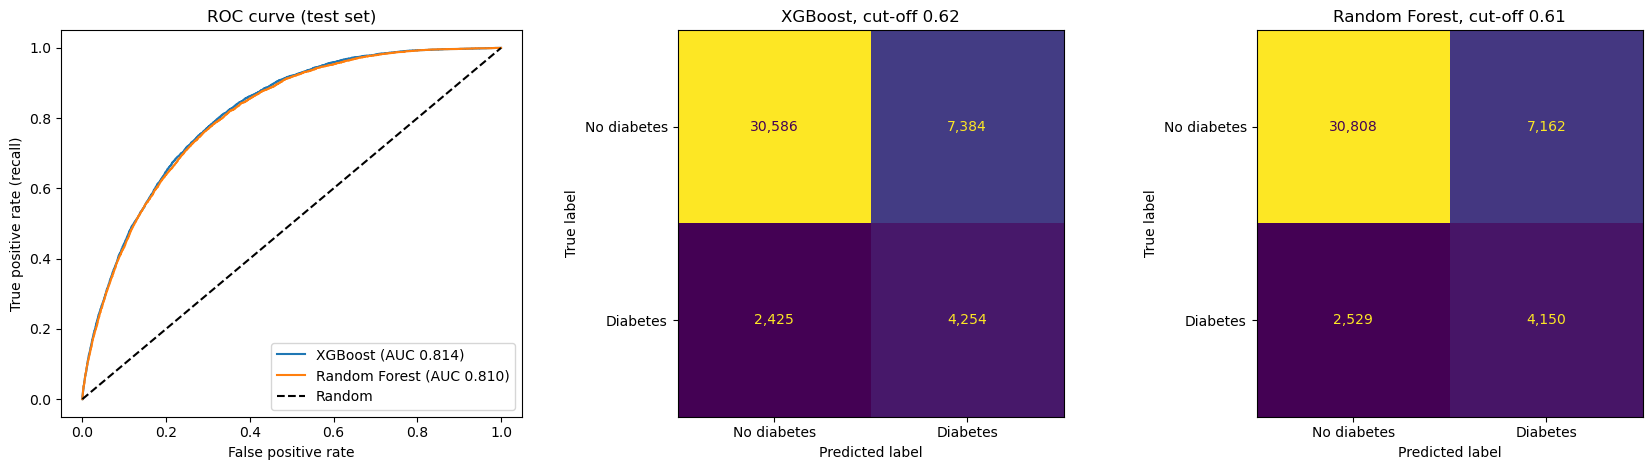

In [46]:
# ROC curves and confusion matrices at the tuned cut-off
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name in ["XGBoost - balanced + settings", "Random Forest - balanced + settings"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[0].plot(fpr, tpr, label=f"{name.split(' -')[0]} (AUC {results[name]['Test ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Random")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve (test set)")
axes[0].legend()

for ax, name in zip(axes[1:], ["XGBoost - balanced + settings", "Random Forest - balanced + settings"]):
    ConfusionMatrixDisplay.from_predictions(y_test, (probas[name] >= cutoffs[name]).astype(int),
                                            display_labels=["No diabetes", "Diabetes"],
                                            ax=ax, colorbar=False, values_format=",")
    ax.set_title(f"{name.split(' -')[0]}, cut-off {cutoffs[name]:.2f}")
plt.tight_layout()
plt.show()

In [47]:
# do they find the same people? diabetics in the test set found by each model
xgb_found = (probas["XGBoost - balanced + settings"] >= cutoffs["XGBoost - balanced + settings"]) & (y_test == 1)
rf_found = (probas["Random Forest - balanced + settings"] >= cutoffs["Random Forest - balanced + settings"]) & (y_test == 1)
print("Diabetics in the test set:", (y_test == 1).sum())
print("Found by both:", (xgb_found & rf_found).sum())
print("Only XGBoost:", (xgb_found & ~rf_found).sum())
print("Only Random Forest:", (rf_found & ~xgb_found).sum())

Diabetics in the test set: 6679
Found by both: 4005
Only XGBoost: 249
Only Random Forest: 145


- XGBoost is a little better at ranking people: ROC-AUC 0.814 vs. 0.810, PR-AUC 0.421 vs. 0.417.
- With a tuned cut-off, F1 is almost the same (0.464 vs. 0.461). XGBoost finds a few more diabetics (recall 0.64 vs. 0.62) with the same precision (0.37).
- They mostly find the same people: 4,005 diabetics found by both, 249 only by XGBoost, 145 only by Random Forest.
- XGBoost also trains faster here (about 0.3 s vs. 0.8 s on the balanced data).
- A different kind of model lands in the same place again. This supports section 13: the limit is the 21 features, not the model.